# C1 yield model

Track C, Apetit Climate & Nature Navigator 2026.

This notebook fits the yield model, tests it on seasons it hasn't seen, and predicts yields for every planned parcel in 2027–31. It is step 7 of the farm climate-risk recipe, and the 2041–60 projection (step 8) reuses the fitted models and their error estimates.

There is one model for each region and crop:

- Each farm has its own yield level, learned from its history.
- The weather stress measures from `c1_weather_features.ipynb`, the soil of the fields sown that year, nitrogen, irrigation, spraying and a yearly trend move yields up or down from that level.
- The effects are learned by comparing each farm with itself across seasons, so differences between farms can't be mistaken for weather effects.

Soil enters the model because a farm sows different fields each year. That is also what lets two parcels on the same farm get different predictions.

It needs the outputs of `c1_clean.ipynb` and `c1_weather_features.ipynb`. The code is in `yieldmodel.py`.

## 0. Setup

In [1]:
from pathlib import Path
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from navigator.analysis import yieldcv as cv
from navigator.analysis import yieldmodel as ym

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
PKG = Path(os.environ.get("CCN_PKG", "../APETIT_CLIMATE_NATURE_NAVIGATOR_2026")).resolve()
OUT, RESULTS = Path("outputs"), Path("results")
RESULTS.mkdir(exist_ok=True)
for f in ["c1_model_table.csv", "c1_parcel_year_features.parquet"]:
    assert (OUT / f).exists(), f"run c1_weather_features.ipynb first ({f} missing)"

UNITS = [("FI_SW", "pea"), ("SE_SKANE", "pea"), ("FI_SW", "turnip_rape"),
         ("FI_SW", "potato"), ("FI_SW", "carrot"), ("FI_SW", "spinach")]
LABEL = {("FI_SW", "pea"): "Pea, Finland", ("SE_SKANE", "pea"): "Pea, Sweden", ("FI_SW", "turnip_rape"): "Turnip rape, Finland",
         ("FI_SW", "potato"): "Potato, Finland", ("FI_SW", "carrot"): "Carrot, Finland", ("FI_SW", "spinach"): "Spinach, Finland"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
INK, MODEL_C, BASE_C = "#222222", "#2f6fd6", "#9a9a9a"

## 1. Load the history and the parcel features

In [2]:
hist = pd.read_csv(OUT / "c1_model_table.csv")
parcels = pd.read_parquet(OUT / "c1_parcel_year_features.parquet")
print("farm-years with a yield:", len(hist))
print("parcel-years:", parcels.groupby(["status", "scenario"]).size().to_dict())

farm-years with a yield: 6120
parcel-years: {('declared', 'historical'): 36337, ('planned', 'ssp245'): 12064}


## 2. Fit on all seasons

One model per region and crop, on every season with a recorded yield. The table shows how much yield changes when each measure rises by one standard deviation within a farm. The leftover error is split into the part all farms share in a season (weather the measures miss) and the part that differs from farm to farm.

In [3]:
MODELS = {u: ym.fit(hist[hist["region"].eq(u[0]) & hist["crop"].eq(u[1])], ym.features(u[1])) for u in UNITS}
fit_summary = pd.DataFrame([{"unit": LABEL[u], "farm-years": m["n_rows"], "farms": m["n_farms"],
                             "leftover error (log sd)": m["resid_sd"], "shared by the season": m["resid_sd_shared"],
                             "farm by farm": m["resid_sd_farm"]} for u, m in MODELS.items()]).set_index("unit")
fit_summary.round(3)

,farm-years,farms,leftover error (log sd),shared by the season,farm by farm
unit,,,,,
"Pea, Finland",1043,120,0.100,0.030,0.096
"Pea, Sweden",2683,300,0.108,0.030,0.104
"Turnip rape, Finland",2011,230,0.101,0.022,0.098
"Potato, Finland",136,15,0.065,0.021,0.062
"Carrot, Finland",95,12,0.078,0.038,0.067
"Spinach, Finland",152,16,0.088,0.041,0.079


In [4]:
effects = pd.concat({LABEL[u]: cv.fit_coefficients(hist[hist["region"].eq(u[0]) & hist["crop"].eq(u[1])], ym.features(u[1]))["effect_of_1sd_pct"]
                     for u in UNITS}, axis=1)
effects.round(1)

,"Pea, Finland","Pea, Sweden","Turnip rape, Finland","Potato, Finland","Carrot, Finland","Spinach, Finland"
feature,,,,,,
drought_stage,-6.1,-8.9,-6.4,-10.8,-8.4,-5.1
drought_x_irr,0.0,3.0,0.0,8.3,3.8,0.2
drought_early,-6.4,-1.2,-4.8,-0.2,1.1,-1.9
heat_days_27,-10.1,0.0,-7.2,-3.6,0.1,-2.3
waterlog_clay,0.0,-2.1,-1.1,0.0,0.0,0.0
harvest_rain_14_mm,-1.8,3.9,-0.0,-1.6,0.2,-0.8
immature_gap,0.0,0.0,0.0,-0.7,0.0,0.0
year_c,2.1,-0.9,2.7,2.9,4.3,-1.3
n_mineral_100,-0.2,0.0,-0.0,1.1,1.5,0.7


Read the table as "% change in yield". Drought lowers yields for every crop, and heat at flowering hits Finnish pea and turnip rape hardest. Irrigation offsets part of the drought damage where farms irrigate (Swedish pea, potato, carrot), and spraying offsets blight on potato. Nitrogen matters for potato, carrot and spinach, not for peas, which make their own. The yearly trend adds 2–4% per standard deviation (about 4 years) for most Finnish crops and is flat for Swedish pea and spinach. Soil effects are small, mostly under 3%, but they are what separates parcels on the same farm. A zero means the measure was too rarely non-zero to estimate.

## 3. Test on unseen seasons

For each season from 2012 to 2026, the model is refitted without that season and then predicts it. The comparison is the farm's own average yield from the other seasons, which is the C1 baseline in the challenge package. Two measures:

- Production error: the total of area times yield over all farms with a record that season, compared with the actual total. This is how far off a regional supply estimate would be.
- Farm error: the typical farm-level miss, as a share of the average yield.

In [5]:
def backtest(unit):
    r, c = unit
    d = hist[hist["region"].eq(r) & hist["crop"].eq(c)].dropna(subset=ym.features(c) + ["yield_t_ha"])
    rows = []
    for yr in sorted(d["year"].unique()):
        tr, te = d[d["year"] != yr], d[d["year"] == yr]
        pred = ym.predict(ym.fit(tr, ym.features(c)), te)
        base = te["farm_id"].map(tr.groupby("farm_id")["yield_t_ha"].mean())
        ok = base.notna()
        te, pred, base = te[ok], pred[ok], base[ok]
        a = te["area_ha"]
        rows.append({"region": r, "crop": c, "year": yr, "farms": len(te), "area_ha": a.sum(),
                     "actual_t": (a * te["yield_t_ha"]).sum(), "model_t": (a * pred).sum(), "baseline_t": (a * base).sum(),
                     "farm_rmse_model": np.sqrt(((te["yield_t_ha"] - pred) ** 2).mean()),
                     "farm_rmse_baseline": np.sqrt(((te["yield_t_ha"] - base) ** 2).mean()),
                     "mean_yield": te["yield_t_ha"].mean()})
    return rows

bt = pd.DataFrame([row for u in UNITS for row in backtest(u)])
bt["production_error_model_pct"] = 100 * (bt["model_t"] / bt["actual_t"] - 1)
bt["production_error_baseline_pct"] = 100 * (bt["baseline_t"] / bt["actual_t"] - 1)
g = bt.groupby(["region", "crop"], sort=False)
backtest_summary = pd.DataFrame({
    "seasons": g.size(),
    "production error, model (%)": g["production_error_model_pct"].apply(lambda s: s.abs().mean()),
    "production error, baseline (%)": g["production_error_baseline_pct"].apply(lambda s: s.abs().mean()),
    "farm error, model (% of mean)": 100 * g["farm_rmse_model"].mean() / g["mean_yield"].mean(),
    "farm error, baseline (% of mean)": 100 * g["farm_rmse_baseline"].mean() / g["mean_yield"].mean(),
})
backtest_summary.index = [LABEL[u] for u in backtest_summary.index]
print("all units, production error: model", round(bt["production_error_model_pct"].abs().mean(), 1),
      "% vs baseline", round(bt["production_error_baseline_pct"].abs().mean(), 1), "%")
backtest_summary.round(1)

all units, production error: model 4.1 % vs baseline 11.0 %


,seasons,"production error, model (%)","production error, baseline (%)","farm error, model (% of mean)","farm error, baseline (% of mean)"
"Pea, Finland",15,3.5,16.4,11.6,21.3
"Pea, Sweden",9,4.2,10.5,12.2,17.4
"Turnip rape, Finland",15,2.9,15.7,11.3,20.6
"Potato, Finland",15,4.2,10.0,8.4,13.9
"Carrot, Finland",15,5.1,7.6,8.9,12.2
"Spinach, Finland",15,4.7,5.8,10.3,11.0


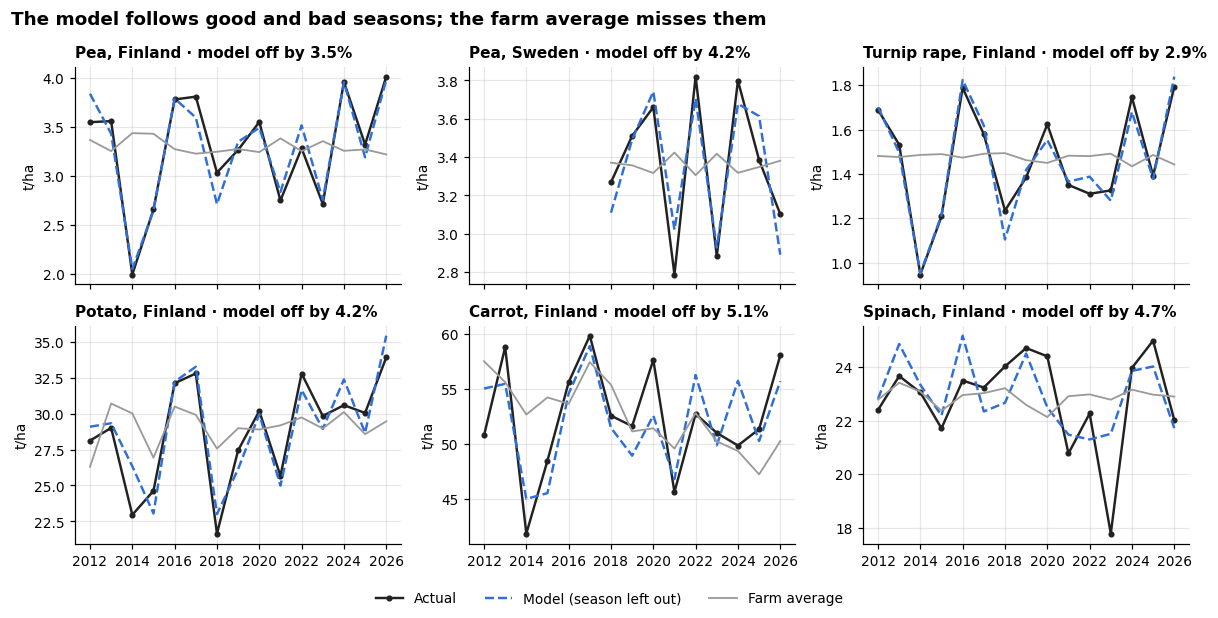

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), sharex=True)
for ax, u in zip(axes.flat, UNITS):
    b = bt[bt["region"].eq(u[0]) & bt["crop"].eq(u[1])]
    ax.plot(b["year"], b["actual_t"] / b["area_ha"], color=INK, marker="o", ms=3, lw=1.6, label="Actual")
    ax.plot(b["year"], b["model_t"] / b["area_ha"], color=MODEL_C, lw=1.6, ls="--", label="Model (season left out)")
    ax.plot(b["year"], b["baseline_t"] / b["area_ha"], color=BASE_C, lw=1.2, label="Farm average")
    err = b["production_error_model_pct"].abs().mean()
    ax.set_title(f"{LABEL[u]} · model off by {err:.1f}%", loc="left")
    ax.set_ylabel("t/ha"); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.suptitle("The model follows good and bad seasons; the farm average misses them", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(RESULTS / "yield_backtest.png", dpi=150, bbox_inches="tight")
plt.show()

Each line is the area-weighted average yield of the farms that reported that season. The model was never shown the season it predicts. It catches the bad seasons for pea, turnip rape and potato (2014, 2018, 2021, 2023) and the good ones, which the farm average can't do by design. Its biggest miss is spinach in 2023, the dry early summer, which hit spinach harder than the model expects; spinach has only 16 farms, so its effects are the least certain.

## 4. Management in future seasons

Nitrogen, irrigation and spraying for 2027–31 are unknown, so each farm keeps what it did in its last three recorded seasons of that crop. A farm with no record for that crop gets the regional median. These are assumptions for the reviewer, not forecasts.

In [7]:
per_farm, per_unit = ym.management_defaults(hist)
per_unit.index = [LABEL[u] for u in per_unit.index]
per_unit.round(2)

,n_mineral_kg_ha,irrigated,sprays
"Carrot, Finland",101.60,1.0,5.0
"Pea, Finland",24.60,0.0,2.0
"Potato, Finland",92.40,1.0,8.6
"Spinach, Finland",132.85,0.0,2.0
"Turnip rape, Finland",92.80,0.0,3.0
"Pea, Sweden",25.00,0.0,NaN


## 5. Predict every planned parcel, 2027–31

Each planned parcel gets its own soil features, its weather cell's stress measures for that season under ssp245, and its farm's management. Predictions are in tonnes per hectare.

Is it fair to apply a model fitted on farm averages to single parcels? To check, the same method predicts every parcel in the past seasons. Those parcel predictions are then averaged back up to farms, weighted by area, and compared with the farm-level prediction.

In [8]:
_, unit_mgmt = ym.management_defaults(hist)          # regional medians, for farms with no record of the crop

def assemble(rows):
    """Add soil features and fill missing management with the regional median, then build model columns."""
    x = rows.reset_index(drop=True)
    x = x.join(ym.parcel_soil_features(x))
    keys = list(zip(x["region"], x["crop"]))
    for col in ym.MANAGEMENT:
        default = pd.Series([unit_mgmt[col].get(k, np.nan) for k in keys], index=x.index)
        x[col] = pd.to_numeric(x[col], errors="coerce").fillna(default)
    x["sprays"] = x["sprays"].fillna(0.0)
    return cv.add_model_columns(x)

def predict_rows(x):
    out = pd.Series(np.nan, index=x.index)
    for u in UNITS:
        i = x["region"].eq(u[0]) & x["crop"].eq(u[1])
        out[i] = ym.predict(MODELS[u], x[i])
    return out

# 2027-31: each farm keeps the management of its last three recorded seasons
future = assemble(parcels[parcels["status"].eq("planned")].merge(per_farm, on=["region", "farm_id", "crop"], how="left"))
future["yield_t_ha_pred"] = predict_rows(future)
print("planned parcel-years predicted:", int(future["yield_t_ha_pred"].notna().sum()), "of", len(future))

# Past seasons: management as recorded, to compare parcel predictions with farm predictions
recorded = hist[["region", "farm_id", "crop", "year"] + ym.MANAGEMENT]
past = assemble(parcels[parcels["status"].eq("declared")].merge(recorded, on=["region", "farm_id", "crop", "year"], how="inner"))
past["pred_t"] = predict_rows(past) * past["parcel_area_ha"]
agg = past.groupby(["farm_id", "crop", "year"])[["pred_t", "parcel_area_ha"]].sum()
from_parcels = agg["pred_t"] / agg["parcel_area_ha"]
from_farm = pd.Series(predict_rows(cv.add_model_columns(hist)).values,
                      index=pd.MultiIndex.from_frame(hist[["farm_id", "crop", "year"]]))
gap = 100 * (from_parcels / from_farm.reindex(from_parcels.index) - 1)
print(f"parcel predictions averaged to farms vs farm-level predictions: median gap {gap.abs().median():.2f}%, "
      f"95th percentile {gap.abs().quantile(0.95):.2f}%  ({len(gap)} farm-years)")

planned parcel-years predicted: 12064 of 12064


parcel predictions averaged to farms vs farm-level predictions: median gap 0.01%, 95th percentile 0.52%  (6120 farm-years)


## 6. Outlook for 2027–31

Predicted yields come out 8–14% above the historical average for most crops, for two reasons:

- The weather. The package's ssp245 run for 2027–31 has cool summers. Finland's June–August average is 16.0 °C against 16.85 °C in 2011–26, with under one day above 27 °C per summer, and Sweden's run is similar. That lifts both pea regions by about 10%. It is one weather run, and these five years happen to be cool; the 2041–60 years of the same scenario are much hotter.
- The yearly trend. Compared with the average historical season, the trend adds about 5–11%, and it is the main reason for the rise in potato and carrot. Only 1.5–3% of it comes after 2026.

The first table gives each crop's outlook. The second splits the change from the historical average into weather, trend, and soil and management, using the model's own coefficients.

In [9]:
frozen = future.copy(); frozen["year_c"] = 2026 - 2019
future["yield_t_ha_pred_no_trend"] = predict_rows(frozen)

def area_mean(df, col, w="parcel_area_ha"):
    return (df[col] * df[w]).sum() / df[w].sum()

def by_year_mean(df, col, w):
    t = df.assign(_v=df[col] * df[w]).groupby("year")[["_v", w]].sum()
    return t["_v"] / t[w]

rows = []
for u in UNITS:
    f = future[future["region"].eq(u[0]) & future["crop"].eq(u[1])]
    h = hist[hist["region"].eq(u[0]) & hist["crop"].eq(u[1])]
    h_mean = (h["yield_t_ha"] * h["area_ha"]).sum() / h["area_ha"].sum()
    row = {"unit": LABEL[u], "history mean (t/ha)": h_mean,
           "2027-31 mean (t/ha)": area_mean(f, "yield_t_ha_pred"),
           "trend after 2026 (%)": 100 * (area_mean(f, "yield_t_ha_pred") / area_mean(f, "yield_t_ha_pred_no_trend") - 1)}
    row["change vs history (%)"] = 100 * (row["2027-31 mean (t/ha)"] / h_mean - 1)
    for yr in range(2027, 2032):
        fy = f[f["year"].eq(yr)]
        row[f"{yr} production (t)"] = (fy["yield_t_ha_pred"] * fy["parcel_area_ha"]).sum()
    rows.append(row)
outlook = pd.DataFrame(rows).set_index("unit")
outlook.round(2)

,history mean (t/ha),2027-31 mean (t/ha),trend after 2026 (%),change vs history (%),2027 production (t),2028 production (t),2029 production (t),2030 production (t),2031 production (t)
unit,,,,,,,,,
"Pea, Finland",3.29,3.74,1.57,13.85,8248.60,7538.28,8602.80,7528.59,7790.41
"Pea, Sweden",3.36,3.66,-1.01,8.65,19180.03,14514.29,19139.77,14876.73,21005.30
"Turnip rape, Finland",1.47,1.62,2.00,10.29,7549.15,7085.66,8556.29,7556.02,8022.04
"Potato, Finland",29.15,32.07,2.13,10.01,8601.18,9330.35,8826.23,9165.45,8394.27
"Carrot, Finland",51.60,56.91,3.33,10.29,8711.48,10339.88,10896.29,10905.80,9469.84
"Spinach, Finland",22.92,22.35,-0.98,-2.51,6881.54,6616.27,8114.76,7711.84,7400.38


In [10]:
WEATHER = ["drought_stage", "drought_x_irr", "drought_early", "heat_days_27", "waterlog_clay", "harvest_rain_14_mm",
           "immature_gap", "may_tmean_c", "blight_days", "blight_x_sprays"]
rows = []
for u in UNITS:
    m = MODELS[u]
    h = hist[hist["region"].eq(u[0]) & hist["crop"].eq(u[1])]
    f = future[future["region"].eq(u[0]) & future["crop"].eq(u[1])]
    shift = {c: area_mean(f, c) - area_mean(h, c, "area_ha") for c in m["features"]}
    part = lambda cols: 100 * (np.exp(sum(m["beta"][c] * shift[c] for c in cols if c in shift)) - 1)
    rows.append({"unit": LABEL[u],
                 "heat days at flowering, history": area_mean(h, "heat_days_27", "area_ha"),
                 "heat days at flowering, 2027-31": area_mean(f, "heat_days_27"),
                 "drought stress, history": area_mean(h, "drought_stage", "area_ha"),
                 "drought stress, 2027-31": area_mean(f, "drought_stage"),
                 "weather effect (%)": part(WEATHER), "trend effect (%)": part(["year_c"]),
                 "soil and management effect (%)": part(ym.SOIL_FEATURES + ["n_mineral_100"])})
pd.DataFrame(rows).set_index("unit").round(2)

,"heat days at flowering, history","heat days at flowering, 2027-31","drought stress, history","drought stress, 2027-31",weather effect (%),trend effect (%),soil and management effect (%)
unit,,,,,,,
"Pea, Finland",2.74,0.06,0.45,0.47,9.74,4.88,0.08
"Pea, Sweden",0.23,0.02,0.54,0.41,10.29,-2.30,0.16
"Turnip rape, Finland",2.20,0.07,0.44,0.42,5.69,6.17,-0.27
"Potato, Finland",3.23,0.11,0.45,0.49,2.84,6.45,0.32
"Carrot, Finland",0.15,0.02,0.46,0.46,0.82,10.76,-0.96
"Spinach, Finland",0.05,0.00,0.37,0.31,1.34,-2.96,-0.21


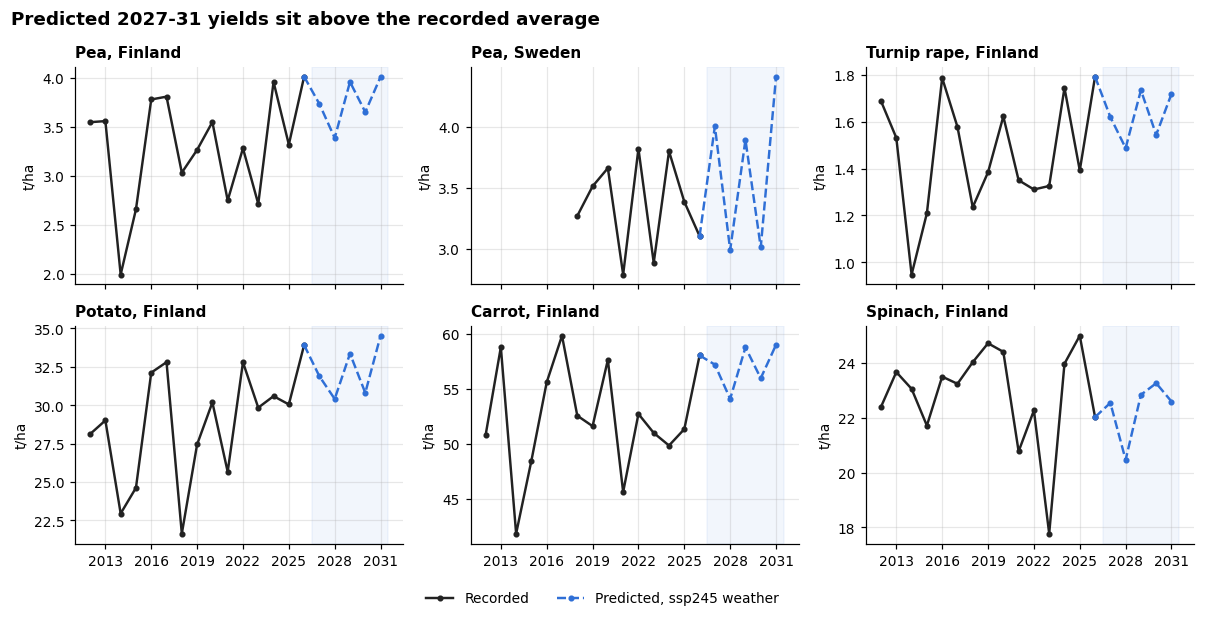

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), sharex=True)
for ax, u in zip(axes.flat, UNITS):
    h = hist[hist["region"].eq(u[0]) & hist["crop"].eq(u[1])]
    hy = by_year_mean(h, "yield_t_ha", "area_ha")
    f = future[future["region"].eq(u[0]) & future["crop"].eq(u[1])]
    fy = by_year_mean(f, "yield_t_ha_pred", "parcel_area_ha")
    ax.plot(hy.index, hy.values, color=INK, marker="o", ms=3, lw=1.6, label="Recorded")
    ax.plot([hy.index[-1]] + list(fy.index), [hy.values[-1]] + list(fy.values), color=MODEL_C, marker="o", ms=3, lw=1.6, ls="--", label="Predicted, ssp245 weather")
    ax.axvspan(2026.5, 2031.5, color=MODEL_C, alpha=0.06)
    ax.set_title(LABEL[u], loc="left"); ax.set_ylabel("t/ha"); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Predicted 2027-31 yields sit above the recorded average", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(RESULTS / "yield_outlook_2027_2031.png", dpi=150, bbox_inches="tight")
plt.show()

Swedish peas swing from season to season because drought stress in the delivered weather does: high in 2028 and 2030, almost none in 2031. The 2031 prediction is above anything recorded, because no recorded season had drought stress that low, so the model is stretching beyond its history there. The same swings appear in the recorded Swedish seasons since 2021.

## 7. Checks
If any check fails, the notebook stops before writing anything.

In [12]:
template = pd.read_csv(PKG / "tasks/templates/C1_yields_2027_2031_submission.csv")
sub = template.drop(columns="yield_t_ha_pred").merge(
    future[["parcel_id", "farm_id", "year", "crop", "parcel_area_ha", "yield_t_ha_pred"]],
    on=["parcel_id", "farm_id", "year", "crop"], how="left")
ranges = hist.groupby(["region", "crop"])["yield_t_ha"].agg(["min", "max"])
lo = future.set_index(["region", "crop"]).index.map(ranges["min"]); hi = future.set_index(["region", "crop"]).index.map(ranges["max"])
checks = {
    "every template row has a prediction": sub["yield_t_ha_pred"].notna().all() and len(sub) == len(template),
    "template areas match the parcels": np.allclose(sub["area_ha"], sub["parcel_area_ha"], atol=0.01),
    "all predictions positive": (future["yield_t_ha_pred"] > 0).all(),
    "predictions inside 0.5x-1.5x of the recorded range": ((future["yield_t_ha_pred"] > 0.5 * lo) & (future["yield_t_ha_pred"] < 1.5 * hi)).all(),
    "parcel and farm predictions agree (median gap < 2%)": gap.abs().median() < 2,
    "model beats the farm average on production for every unit": (backtest_summary["production error, model (%)"] < backtest_summary["production error, baseline (%)"]).all(),
}
for k, ok in checks.items():
    print(("PASS " if ok else "FAIL ") + k)
assert all(checks.values())

PASS every template row has a prediction
PASS template areas match the parcels
PASS all predictions positive
PASS predictions inside 0.5x-1.5x of the recorded range
PASS parcel and farm predictions agree (median gap < 2%)
PASS model beats the farm average on production for every unit


## 8. Write the outputs

In [13]:
sub[["parcel_id", "farm_id", "region", "year", "crop", "area_ha", "yield_t_ha_pred"]].round({"yield_t_ha_pred": 3}).to_csv(
    OUT / "c1_yield_predictions_2027_2031.csv", index=False)
future.to_parquet(OUT / "c1_parcel_predictions.parquet", index=False)
outlook.to_csv(OUT / "production_outlook_2027_2031.csv")
model_file = {f"{r}/{c}": m for (r, c), m in MODELS.items()}
_ = (OUT / "yield_model.json").write_text(json.dumps(model_file, indent=1))

# Versioned record (no farm-level detail, no timestamps)
summary = {k: {kk: v for kk, v in m.items() if kk != "farm_level"} for k, m in model_file.items()}
_ = (RESULTS / "yield_model.json").write_text(json.dumps(summary, indent=1))
bt.round(4).to_csv(RESULTS / "yield_backtest.csv", index=False)
backtest_summary.round(3).to_csv(RESULTS / "yield_backtest_summary.csv")
for f in ["c1_yield_predictions_2027_2031.csv", "c1_parcel_predictions.parquet", "production_outlook_2027_2031.csv", "yield_model.json"]:
    print(f"outputs/{f:38s} {(OUT / f).stat().st_size / 1e6:6.2f} MB")
for f in ["yield_model.json", "yield_backtest.csv", "yield_backtest_summary.csv", "yield_backtest.png", "yield_outlook_2027_2031.png"]:
    print(f"results/{f:38s} {(RESULTS / f).stat().st_size / 1e6:6.2f} MB  (versioned)")

outputs/c1_yield_predictions_2027_2031.csv       0.57 MB
outputs/c1_parcel_predictions.parquet            0.73 MB
outputs/production_outlook_2027_2031.csv         0.00 MB
outputs/yield_model.json                         0.03 MB
results/yield_model.json                         0.01 MB  (versioned)
results/yield_backtest.csv                       0.01 MB  (versioned)
results/yield_backtest_summary.csv               0.00 MB  (versioned)
results/yield_backtest.png                       0.28 MB  (versioned)
results/yield_outlook_2027_2031.png              0.18 MB  (versioned)


## Points for the method note

- The model compares each farm with itself across seasons. Farm skill, typical soil and management set the farm's level; weather, the fields sown that season and management changes move it.
- On seasons it hadn't seen, the model's regional production estimate was off by about 4% on average, against about 11% for the farm average (section 3).
- What it can't explain splits into a part shared by all farms in a season and a larger part that differs farm by farm (section 2). The 2041–60 risk step simulates both, because a shared shortfall is what hurts supply.
- Management for 2027–31 assumes each farm keeps its recent practice (section 4), and the yearly trend continues. The predicted rise for 2027–31 comes from cool summers in the package's single ssp245 weather run (mainly peas) and from the trend (mainly potato and carrot); section 6 splits it.
- Parcel predictions come from the same model applied to each parcel's soil and weather cell. Averaged back to farms, they match the farm-level predictions closely (section 5).